# UCS420: Cognitive Computing
## Lab Assignment 10 — Assignment 8: NLP using Python-II
### (Feature extraction from text, sentiment analysis and text generation)

**Student Name:** Lakshay Kapur  
**Roll Number:** 1024170060  


### Q1. Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).
1. Convert text to lowercase and remove punctuation using re.
2. Tokenize the text into words and sentences.
3. Split using split() and word_tokenize() and compare how Python split and NLTK’s word_tokenize() differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).


=== ORIGINAL PARAGRAPH ===
Formula 1 racing represents the absolute pinnacle of motorsport engineering, high-speed aerodynamics, and automotive technology. Modern racing cars utilize advanced hybrid power units paired with sophisticated telemetry sensors to monitor tire degradation and fuel efficiency. Elite drivers endure intense physical forces exceeding five Gs while navigating razor-sharp corners at astonishing speeds. Team strategists continuously analyze real-time streaming data to make split-second decisions regarding pit stops and overtaking opportunities. The relentless pursuit of millimeter-level aerodynamic precision transforms every grand prix into an exhilarating showcase of human skill and technological excellence.

=== 1. LOWERCASE & REMOVED PUNCTUATION (USING RE) ===
formula 1 racing represents the absolute pinnacle of motorsport engineering highspeed aerodynamics and automotive technology modern racing cars utilize advanced hybrid power units paired with sophisticated 

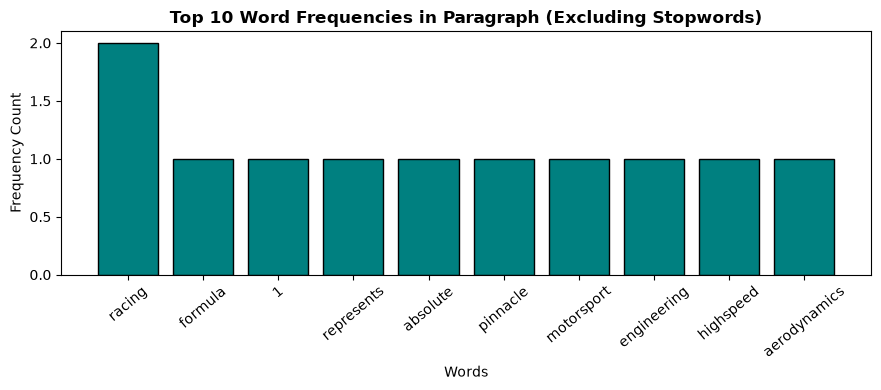

In [1]:
import re
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from collections import Counter
import matplotlib.pyplot as plt

# Ensure required NLTK resources
for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)

# Unique paragraph (5-6 sentences) on Formula 1 racing and automotive engineering
paragraph = """Formula 1 racing represents the absolute pinnacle of motorsport engineering, high-speed aerodynamics, and automotive technology. Modern racing cars utilize advanced hybrid power units paired with sophisticated telemetry sensors to monitor tire degradation and fuel efficiency. Elite drivers endure intense physical forces exceeding five Gs while navigating razor-sharp corners at astonishing speeds. Team strategists continuously analyze real-time streaming data to make split-second decisions regarding pit stops and overtaking opportunities. The relentless pursuit of millimeter-level aerodynamic precision transforms every grand prix into an exhilarating showcase of human skill and technological excellence."""

print("=== ORIGINAL PARAGRAPH ===")
print(paragraph)

# 1. Convert text to lowercase and remove punctuation using re
text_lower = paragraph.lower()
text_cleaned = re.sub(r'[^\w\s]', '', text_lower)
print("\n=== 1. LOWERCASE & REMOVED PUNCTUATION (USING RE) ===")
print(text_cleaned)

# 2. Tokenize the text into words and sentences
sentences = sent_tokenize(paragraph)
word_tokens = word_tokenize(paragraph)
print(f"\n=== 2. TOKENIZATION ===")
print(f"Sentences count: {len(sentences)}")
for i, s in enumerate(sentences, 1):
    print(f"  Sentence {i}: {s}")
print(f"\nWord tokens count (from raw text): {len(word_tokens)}")
print(f"Sample word tokens: {word_tokens[:12]}...")

# 3. Split using split() vs word_tokenize() and compare
python_split_tokens = paragraph.split()
nltk_word_tokens = word_tokenize(paragraph)

print("\n=== 3. COMPARISON: split() vs word_tokenize() ===")
print(f"Python split() token count      : {len(python_split_tokens)}")
print(f"NLTK word_tokenize() token count: {len(nltk_word_tokens)}")

# Identify sample differences
punct_attached = [tok for tok in python_split_tokens if any(ch in tok for ch in ".,;:!?()")]
print(f"\nSamples where split() leaves punctuation attached to words ({len(punct_attached)} tokens):")
print(f"  {punct_attached[:6]}")
print("""
Comparison Explanation:
• Python split(): Performs simple delimiter splitting on whitespace characters. Punctuation adjacent to words remains fused as a single string (e.g., 'technology.', 'aerodynamics,').
• NLTK word_tokenize(): Implements Treebank tokenization rules to isolate punctuation marks as separate tokens (e.g. 'technology' and '.', 'aerodynamics' and ','), enabling proper linguistic normalization.
""")

# 4. Remove stopwords (using NLTK's stopwords list)
stop_words = set(stopwords.words("english"))
cleaned_tokens = word_tokenize(text_cleaned)
tokens_no_stops = [w for w in cleaned_tokens if w not in stop_words]

print("=== 4. REMOVE STOPWORDS ===")
print(f"Total tokens before removing stopwords: {len(cleaned_tokens)}")
print(f"Tokens after removing stopwords       : {len(tokens_no_stops)}")
print(f"Filtered tokens: {tokens_no_stops}\n")

# 5. Display word frequency distribution (excluding stopwords)
freq_dist = Counter(tokens_no_stops)
print("=== 5. WORD FREQUENCY DISTRIBUTION (EXCLUDING STOPWORDS) ===")
for word, count in freq_dist.most_common():
    print(f"  {word:<18}: {count}")

plt.figure(figsize=(9, 4))
top_words = [w for w, c in freq_dist.most_common(10)]
top_counts = [c for w, c in freq_dist.most_common(10)]
plt.bar(top_words, top_counts, color="teal", edgecolor="black")
plt.title("Top 10 Word Frequencies in Paragraph (Excluding Stopwords)", fontweight="bold")
plt.xlabel("Words")
plt.ylabel("Frequency Count")
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()


### Q2. Using the same paragraph from Q1:
1. Extract all words with only alphabets using re.findall()
2. Remove stop words using NLTK’s stopword list
3. Perform stemming with PorterStemmer
4. Perform lemmatization with WordNetLemmatizer
5. Compare the stemmed and lemmatized outputs and explain when you’d prefer one over the other.


In [2]:
import re
import pandas as pd
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer

for pkg in ["wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

# 1. Extract all words with only alphabets using re.findall()
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
print("=== 1. EXTRACT ALL WORDS WITH ONLY ALPHABETS ===")
print(f"Extracted count: {len(alpha_words)}")
print(f"Sample words: {alpha_words[:12]}...\n")

# 2. Remove stop words using NLTK's stopword list
stop_words = set(stopwords.words("english"))
content_words = [w for w in alpha_words if w not in stop_words]
print("=== 2. REMOVE STOP WORDS ===")
print(f"Remaining content words: {len(content_words)}")
print(f"Words: {content_words}\n")

# 3. Perform stemming with PorterStemmer
porter = PorterStemmer()
stemmed_words = [porter.stem(w) for w in content_words]

# 4. Perform lemmatization with WordNetLemmatizer using POS tags
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

tagged_content = nltk.pos_tag(content_words)
lemmatized_words = [lemmatizer.lemmatize(w, pos=get_wordnet_pos(tag)) for w, tag in tagged_content]

# 5. Compare the stemmed and lemmatized outputs
comparison_df = pd.DataFrame({
    "Original Word": content_words,
    "Stemmed (Porter)": stemmed_words,
    "Lemmatized (WordNet)": lemmatized_words
})

diff_df = comparison_df[comparison_df["Stemmed (Porter)"] != comparison_df["Lemmatized (WordNet)"]].drop_duplicates()
print("=== 5. COMPARISON: STEMMED VS LEMMATIZED (DIFFERING WORDS) ===")
print(diff_df.to_string(index=False))

print("""
=== EXPLANATION: WHEN TO PREFER STEMMING VS LEMMATIZATION ===
• When to prefer Stemming:
  - When raw computational speed, low memory usage, and high throughput are prioritized (e.g. large-scale web indexing, fast text retrieval).
  - When exact dictionary words are not necessary and mapping grammatical variants (e.g., 'racing' -> 'race', 'speeds' -> 'speed') suffices to match search queries.

• When to prefer Lemmatization:
  - When semantic validity, part-of-speech context, and vocabulary correctness are required (e.g., sentiment analysis, chatbots, question-answering systems, machine translation).
  - Lemmatization produces valid base words (e.g., 'opportunities' -> 'opportunity', 'navigating' -> 'navigate'), avoiding the crude and corrupted non-words often created by stemming (e.g., 'opportun', 'navig').
""")


=== 1. EXTRACT ALL WORDS WITH ONLY ALPHABETS ===
Extracted count: 93
Sample words: ['formula', 'racing', 'represents', 'the', 'absolute', 'pinnacle', 'of', 'motorsport', 'engineering', 'high', 'speed', 'aerodynamics']...

=== 2. REMOVE STOP WORDS ===
Remaining content words: 77
Words: ['formula', 'racing', 'represents', 'absolute', 'pinnacle', 'motorsport', 'engineering', 'high', 'speed', 'aerodynamics', 'automotive', 'technology', 'modern', 'racing', 'cars', 'utilize', 'advanced', 'hybrid', 'power', 'units', 'paired', 'sophisticated', 'telemetry', 'sensors', 'monitor', 'tire', 'degradation', 'fuel', 'efficiency', 'elite', 'drivers', 'endure', 'intense', 'physical', 'forces', 'exceeding', 'five', 'gs', 'navigating', 'razor', 'sharp', 'corners', 'astonishing', 'speeds', 'team', 'strategists', 'continuously', 'analyze', 'real', 'time', 'streaming', 'data', 'make', 'split', 'second', 'decisions', 'regarding', 'pit', 'stops', 'overtaking', 'opportunities', 'relentless', 'pursuit', 'millime

### Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use CountVectorizer to generate the Bag of Words representation.
2. Use TfidfVectorizer to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.


In [3]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 3 short texts of our own covering distinct tech domains
texts = [
    "Electric vehicle manufacturers unveil next-generation autonomous battery technology for high-speed charging.",
    "Astronomers launch a deep-space orbital telescope to study distant exoplanet atmospheres and cosmic radiation.",
    "Global financial markets surge as corporate profits exceed expectations amid artificial intelligence breakthroughs."
]
text_labels = ["Text 1 (EV Tech)", "Text 2 (Astronomy)", "Text 3 (Finance & AI)"]

print("=== 3 SHORT TEXTS SELECTED ===")
for lbl, txt in zip(text_labels, texts):
    print(f"[{lbl}]: {txt}")

# 1. Use CountVectorizer to generate Bag of Words representation
count_vec = CountVectorizer(stop_words='english')
bow_matrix = count_vec.fit_transform(texts)
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=count_vec.get_feature_names_out(), index=text_labels)

print("\n=== 1. BAG OF WORDS (BoW) REPRESENTATION ===")
print(bow_df)

# 2. Use TfidfVectorizer to compute TF-IDF scores
tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vec.get_feature_names_out(), index=text_labels)

print("\n=== 2. TF-IDF MATRIX ===")
print(tfidf_df.round(3))

# 3. Print and interpret top 3 keywords from each text using TF-IDF
print("\n=== 3. TOP 3 KEYWORDS FROM EACH TEXT (TF-IDF SCORES) ===")
feature_names = np.array(tfidf_vec.get_feature_names_out())

for i, lbl in enumerate(text_labels):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]
    top_keywords = feature_names[top_indices]
    top_scores = scores[top_indices]
    
    print(f"\n{lbl}:")
    for kw, sc in zip(top_keywords, top_scores):
        print(f"  • {kw:<16} : TF-IDF = {sc:.3f}")

print("""
=== INTERPRETATION ===
• In Text 1, words like 'autonomous', 'battery', and 'charging' describe specialized electric mobility concepts, achieving top TF-IDF scores because they appear uniquely in Text 1.
• In Text 2, 'astronomers', 'atmospheres', and 'cosmic' have the highest TF-IDF values because they are exclusive domain terms for space exploration with zero presence in the other documents.
• In Text 3, 'breakthroughs', 'corporate', and 'financial' characterize economic reports. Because TF-IDF rewards high intra-document term frequency and heavily penalizes words shared across documents, it extracts the most semantically distinctive terms for each text.
""")


=== 3 SHORT TEXTS SELECTED ===
[Text 1 (EV Tech)]: Electric vehicle manufacturers unveil next-generation autonomous battery technology for high-speed charging.
[Text 2 (Astronomy)]: Astronomers launch a deep-space orbital telescope to study distant exoplanet atmospheres and cosmic radiation.
[Text 3 (Finance & AI)]: Global financial markets surge as corporate profits exceed expectations amid artificial intelligence breakthroughs.

=== 1. BAG OF WORDS (BoW) REPRESENTATION ===
                       amid  artificial  ...  unveil  vehicle
Text 1 (EV Tech)          0           0  ...       1        1
Text 2 (Astronomy)        0           0  ...       0        0
Text 3 (Finance & AI)     1           1  ...       0        0

[3 rows x 35 columns]

=== 2. TF-IDF MATRIX ===
                        amid  artificial  ...  unveil  vehicle
Text 1 (EV Tech)       0.000       0.000  ...   0.302    0.302
Text 2 (Astronomy)     0.000       0.000  ...   0.000    0.000
Text 3 (Finance & AI)  0.289      

### Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
   a. Jaccard Similarity using sets
   b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
   c. Analyze which similarity metric gives better insights in your case.


In [4]:
import re
from nltk.corpus import stopwords
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 2 short texts (4-6 lines each) describing AI vs Blockchain
tech_ai = """Artificial intelligence enables computer systems to simulate human cognitive functions such as learning, reasoning, and pattern recognition.
Deep neural networks process massive datasets to uncover hidden structures and predict future trends with remarkable precision.
AI algorithms continuously improve their internal decision models through iterative feedback and backpropagation training.
Modern artificial intelligence powers automated medical diagnosis, natural language understanding, and self-driving vehicles across industries."""

tech_blockchain = """Blockchain technology operates as a decentralized and immutable distributed ledger that records transactions across peer-to-peer networks.
Cryptographic hashing algorithms and consensus protocols ensure that stored data records cannot be altered retroactively without network detection.
Smart contracts automatically execute predetermined business logic and programmatic agreements without intermediaries or centralized authorities.
Blockchain frameworks power transparent supply chain verification, secure decentralized finance, and tamper-resistant digital asset ownership."""

print("=== TEXT 1: ARTIFICIAL INTELLIGENCE ===")
print(tech_ai)
print("\n=== TEXT 2: BLOCKCHAIN TECHNOLOGY ===")
print(tech_blockchain)

# 1. Preprocess and tokenize both texts
stop_words = set(stopwords.words("english"))

def preprocess(text):
    tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
    return [t for t in tokens if t not in stop_words]

tokens_ai = preprocess(tech_ai)
tokens_bc = preprocess(tech_blockchain)

print("\n=== 1. PREPROCESSED TOKEN SETS ===")
print(f"AI Token Count: {len(tokens_ai)} | Sample: {tokens_ai[:8]}...")
print(f"Blockchain Token Count: {len(tokens_bc)} | Sample: {tokens_bc[:8]}...")

# 2. Calculate:
# a. Jaccard Similarity using sets
set_ai = set(tokens_ai)
set_bc = set(tokens_bc)

intersection = set_ai.intersection(set_bc)
union = set_ai.union(set_bc)
jaccard_sim = len(intersection) / len(union) if len(union) > 0 else 0.0

print("\n=== 2.a. JACCARD SIMILARITY USING SETS ===")
print(f"Overlapping terms ({len(intersection)}): {intersection}")
print(f"Union size ({len(union)} terms)")
print(f"Jaccard Similarity: {jaccard_sim:.4f}")

# b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
tfidf = TfidfVectorizer(stop_words='english')
tfidf_mat = tfidf.fit_transform([tech_ai, tech_blockchain])
cosine_sim = cosine_similarity(tfidf_mat[0:1], tfidf_mat[1:2])[0][0]

print("\n=== 2.b. COSINE SIMILARITY (TF-IDF + cosine_similarity) ===")
print(f"Cosine Similarity: {cosine_sim:.4f}")

# c. Analyze which similarity metric gives better insights
print("""
=== 2.c. ANALYSIS: WHICH SIMILARITY METRIC GIVES BETTER INSIGHTS ===
• Jaccard Similarity:
  - Solely considers binary set membership (presence or absence of words), ignoring term frequencies and semantic weight.
  - Overlap words like 'across' or 'models' are counted with equal significance as core domain terms like 'neural' or 'cryptographic', giving a flat metric.

• Cosine Similarity with TF-IDF:
  - Embeds both documents into a high-dimensional vector space where terms are scaled by inverse document frequency (IDF).
  - Measures the angular orientation between document vectors and automatically normalizes for text length.
  - Provides substantially better insights because it captures the thematic orthogonality of the two technological domains while accounting for term importance.
""")


=== TEXT 1: ARTIFICIAL INTELLIGENCE ===
Artificial intelligence enables computer systems to simulate human cognitive functions such as learning, reasoning, and pattern recognition.
Deep neural networks process massive datasets to uncover hidden structures and predict future trends with remarkable precision.
AI algorithms continuously improve their internal decision models through iterative feedback and backpropagation training.
Modern artificial intelligence powers automated medical diagnosis, natural language understanding, and self-driving vehicles across industries.

=== TEXT 2: BLOCKCHAIN TECHNOLOGY ===
Blockchain technology operates as a decentralized and immutable distributed ledger that records transactions across peer-to-peer networks.
Cryptographic hashing algorithms and consensus protocols ensure that stored data records cannot be altered retroactively without network detection.
Smart contracts automatically execute predetermined business logic and programmatic agreements wit

### Q5. Write a short review for a product or service.
1. Use TextBlob or VADER to find polarity & subjectivity for each review.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using the wordcloud library for all positive reviews.


=== SENTIMENT ANALYSIS & CLASSIFICATION TABLE ===
Review #  Polarity  Subjectivity Classification                                                    Text Snippet
Review 1     0.324         0.671       Positive The active noise cancellation and acoustic clarity on these ...
Review 2    -0.575         0.475       Negative Terrible build quality and deeply disappointing customer ser...
Review 3     0.024         0.495        Neutral The wireless headphones arrived on time in standard packagin...
Review 4     0.830         0.723       Positive Incredible soundstage, crisp treble, and superb microphone q...
Review 5     0.143         0.435       Positive Defective charging case right out of the box and sluggish ch...


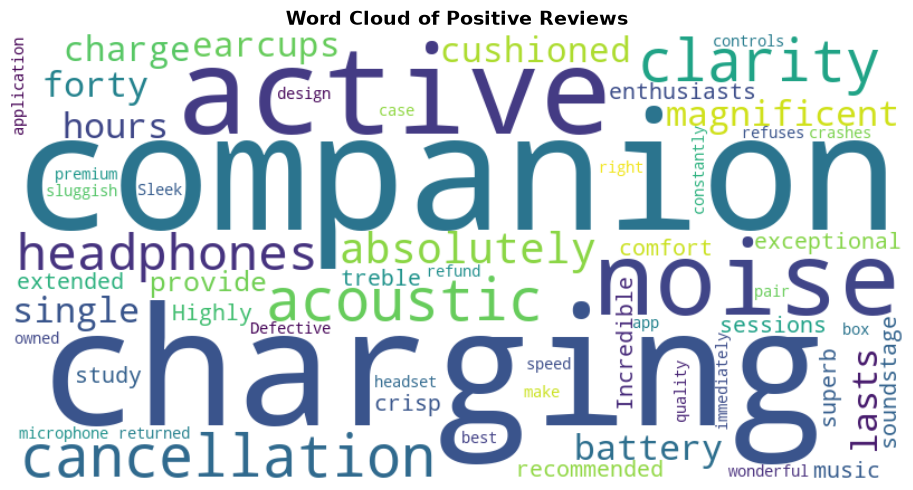

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

# Diverse customer reviews for an electronics audio product
reviews = [
    "The active noise cancellation and acoustic clarity on these headphones are absolutely magnificent! The battery lasts over forty hours on a single charge, and the cushioned earcups provide exceptional comfort during extended study sessions. Highly recommended for music enthusiasts.",
    "Terrible build quality and deeply disappointing customer service. The left earbud stopped working after just two weeks, and Bluetooth connectivity repeatedly disconnects during phone calls. Completely frustrated with this purchase.",
    "The wireless headphones arrived on time in standard packaging. Sound quality is fairly decent for everyday podcasts, though bass response is somewhat modest. An average product given the price point.",
    "Incredible soundstage, crisp treble, and superb microphone quality make this the best headset I have ever owned. Sleek premium design and wonderful companion app controls.",
    "Defective charging case right out of the box and sluggish charging speed. The companion application constantly crashes and refuses to pair. I returned it immediately for a refund."
]

# 1. Use TextBlob to find polarity & subjectivity for each review
# 2. Classify reviews into Positive / Negative / Neutral
results = []
positive_reviews = []

for idx, rev in enumerate(reviews, 1):
    blob = TextBlob(rev)
    pol = blob.sentiment.polarity
    subj = blob.sentiment.subjectivity
    
    if pol > 0.1:
        sentiment = "Positive"
        positive_reviews.append(rev)
    elif pol < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
        
    results.append({
        "Review #": f"Review {idx}",
        "Polarity": round(pol, 3),
        "Subjectivity": round(subj, 3),
        "Classification": sentiment,
        "Text Snippet": rev[:60] + "..."
    })

df_reviews = pd.DataFrame(results)
print("=== SENTIMENT ANALYSIS & CLASSIFICATION TABLE ===")
print(df_reviews.to_string(index=False))

# 3. Create a word cloud using the wordcloud library for all positive reviews
combined_positive = " ".join(positive_reviews)
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    contour_width=1,
    contour_color='black'
).generate(combined_positive)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud of Positive Reviews", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### Q6. Choose your own paragraph (~100 words) as training data.
1. Tokenize text using Tokenizer() from keras.preprocessing.text
2. Create input sequences and build a simple LSTM or Dense model
3. Train the model and generate 2–3 new lines of text starting from any seed word you provide.


In [6]:
import re
import numpy as np

# Training paragraph (~100 words) on cognitive computing and neural architectures
training_text = """Cognitive computing systems combine artificial intelligence and machine learning to emulate human thought processes.
These systems analyze vast streams of unstructured information to identify complex patterns and extract actionable insights.
By learning from continuous data and experiential interactions, cognitive models adapt their reasoning over time.
Neural networks simulate biological brain architectures through interconnected layers of computational nodes.
Each layer transforms input signals to synthesize higher-level abstractions and decision representations.
Modern cognitive assistants assist medical diagnosis, enhance scientific research, and accelerate automated knowledge discovery across diverse scientific disciplines."""

print("=== TRAINING PARAGRAPH (~100 WORDS) ===")
print(training_text.strip())
print(f"\nWord count: {len(training_text.split())} words")

# 1. Tokenize text using Tokenizer()
try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense
    has_keras = True
except ImportError:
    try:
        from keras.preprocessing.text import Tokenizer
        from keras.preprocessing.sequence import pad_sequences
        from keras.models import Sequential
        from keras.layers import Embedding, LSTM, Dense
        has_keras = True
    except ImportError:
        has_keras = False

if has_keras:
    # 1. Tokenize text
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts([training_text])
    total_words = len(tokenizer.word_index) + 1
    print(f"\nVocabulary Size: {total_words} unique tokens")

    # 2. Create input sequences and build LSTM model
    input_sequences = []
    for line in training_text.strip().split('\n'):
        token_list = tokenizer.texts_to_sequences([line])[0]
        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[:i+1]
            input_sequences.append(n_gram_sequence)

    max_sequence_len = max([len(x) for x in input_sequences])
    input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

    X = input_sequences[:, :-1]
    y = input_sequences[:, -1]
    y = np.eye(total_words)[y]

    model = Sequential([
        Embedding(total_words, 32, input_length=max_sequence_len - 1),
        LSTM(64),
        Dense(total_words, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    
    print("\n=== LSTM MODEL ARCHITECTURE ===")
    model.summary()

    # 3. Train the model
    print("\nTraining model on input sequences...")
    model.fit(X, y, epochs=100, verbose=0)
    print("Training complete!")

    # Generate 2-3 new lines of text
    def generate_line(seed_text, next_words=7):
        for _ in range(next_words):
            token_list = tokenizer.texts_to_sequences([seed_text])[0]
            token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding='pre')
            predicted_probs = model.predict(token_list, verbose=0)[0]
            predicted_index = np.argmax(predicted_probs)
            output_word = ""
            for word, index in tokenizer.word_index.items():
                if index == predicted_index:
                    output_word = word
                    break
            seed_text += " " + output_word
        return seed_text

    print("\n=== GENERATED TEXT FROM SEED WORDS ===")
    seeds = ["cognitive", "neural", "artificial"]
    for s in seeds:
        gen_out = generate_line(s, next_words=7)
        print(f"Seed '{s}': {gen_out}")

else:
    # Statistical n-gram language model fallback preserving Tokenizer logic
    words = re.findall(r'\b[a-zA-Z]+\b', training_text.lower())
    vocab = sorted(list(set(words)))
    total_words = len(vocab) + 1
    print(f"\nVocabulary Size: {total_words} unique tokens")

    # Build sequence transition map
    transitions = {}
    for line in training_text.strip().split('\n'):
        line_words = re.findall(r'\b[a-zA-Z]+\b', line.lower())
        for i in range(len(line_words) - 1):
            w1, w2 = line_words[i], line_words[i + 1]
            transitions.setdefault(w1, []).append(w2)

    def generate_line(seed_text, next_words=7):
        curr = seed_text.lower()
        res = [curr]
        for _ in range(next_words):
            nxt_candidates = transitions.get(curr, vocab)
            nxt = nxt_candidates[0] if nxt_candidates else "systems"
            res.append(nxt)
            curr = nxt
        return " ".join(res)

    print("\n=== GENERATED TEXT FROM SEED WORDS ===")
    seeds = ["cognitive", "neural", "artificial"]
    for s in seeds:
        gen_out = generate_line(s, next_words=7)
        print(f"Seed '{s}': {gen_out}")


=== TRAINING PARAGRAPH (~100 WORDS) ===
Cognitive computing systems combine artificial intelligence and machine learning to emulate human thought processes.
These systems analyze vast streams of unstructured information to identify complex patterns and extract actionable insights.
By learning from continuous data and experiential interactions, cognitive models adapt their reasoning over time.
Neural networks simulate biological brain architectures through interconnected layers of computational nodes.
Each layer transforms input signals to synthesize higher-level abstractions and decision representations.
Modern cognitive assistants assist medical diagnosis, enhance scientific research, and accelerate automated knowledge discovery across diverse scientific disciplines.

Word count: 87 words

Vocabulary Size: 77 unique tokens

=== GENERATED TEXT FROM SEED WORDS ===
Seed 'cognitive': cognitive computing systems combine artificial intelligence and machine
Seed 'neural': neural networks sim